# 🟢 AT | Dados para Machine Learning: Feature Engineering

## ⤵️ Imports

In [619]:
!pip install mglearn

In [620]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import FeatureHasher
from sklearn.linear_model import LogisticRegression
from mglearn.tools import visualize_coefficients
from sklearn.metrics import accuracy_score
from sklearn.decomposition import PCA
from nltk.corpus import stopwords
import matplotlib.pyplot as plt
import pandas as pd
import unicodedata
import numpy as np
import kagglehub
import nltk

In [621]:
# Importa a última versão
path = kagglehub.dataset_download("olistbr/brazilian-ecommerce")
print("Path to dataset files:", path)

files = {
    'customers' : 'olist_customers_dataset.csv',
    'geolocation' : 'olist_geolocation_dataset.csv',
    'items' : 'olist_order_items_dataset.csv',
    'payment' : 'olist_order_payments_dataset.csv',
    'orders' : 'olist_orders_dataset.csv',
    'products' : 'olist_products_dataset.csv',
    'sellers' : 'olist_sellers_dataset.csv',
    'review' : 'olist_order_reviews_dataset.csv',
}

# Lê os arquivos armazenando os dados em dataframes
dfs = {}
for file, filename in files.items():
    dfs[file] = pd.read_csv(path + '/' + filename)

# Combina-os em um único dataframe com todas as colunas de interesse:
customers_location = dfs['customers'].merge(dfs['geolocation'], how='inner', left_on='customer_zip_code_prefix', right_on='geolocation_zip_code_prefix').drop_duplicates('customer_id', keep='first')
cusloc_order = customers_location.merge(dfs['orders'], how='inner', on='customer_id')
cuslocord_item = cusloc_order.merge(dfs['items'], how='inner', on='order_id')
cuslocordite_prod = cuslocord_item.merge(dfs['products'], how='inner', on='product_id')
cuslocordite_rev = cuslocordite_prod.merge(dfs['review'], how='left', on='order_id')

Using Colab cache for faster access to the 'brazilian-ecommerce' dataset.
Path to dataset files: /kaggle/input/brazilian-ecommerce


In [622]:
dados = cuslocordite_rev[[
    'customer_unique_id',
    'seller_id',
    'product_id',
    'order_item_id',
    'shipping_limit_date',
    'customer_zip_code_prefix',
    'customer_city',
    'customer_state',
    'order_status',
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_estimated_delivery_date',
    'order_delivered_customer_date',
    'price',
    'freight_value',
    'product_category_name',
    'product_photos_qty',
    'review_score',
    'review_comment_title',
    'review_comment_message',
    'review_creation_date',
    'review_answer_timestamp',
    'geolocation_lat' # Adicionei esta coluna, pois não estava apresentada no enunciado
]]

## 💡 PARTE I | Conceitos

#### **Questão 1:** Examine os dados e, para cada atributo abaixo, diga se o dado seria de natureza numérica, textual, ou categórica.

* customer_id;
* geolocation_lat;
* customer_city;
* review_comment_title;
* freight_value.

In [623]:
q1 = dados[['customer_unique_id', 'geolocation_lat', 'customer_city', 'review_comment_title', 'freight_value']]
q1.head()

,customer_unique_id,geolocation_lat,customer_city,review_comment_title,freight_value
0,861eff4711a542e4b93843c6dd7febb0,-20.509897,franca,NaN,21.88
1,290c77bc529b7ac935b93aa66c333dc3,-23.726853,sao bernardo do campo,NaN,46.48
2,060e732b5b29e8181a18229c7b0b2b5e,-23.527788,sao paulo,NaN,17.79
3,259dac757896d24d7702b9acbbff3f3c,-23.496930,mogi das cruzes,NaN,23.36
4,345ecd01c38d18a9036ed96c73b8d066,-22.987222,campinas,a melhor nota,22.25


In [624]:
q1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 113007 entries, 0 to 113006
Data columns (total 5 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   customer_unique_id    113007 non-null  object 
 1   geolocation_lat       113007 non-null  float64
 2   customer_city         113007 non-null  object 
 3   review_comment_title  13389 non-null   object 
 4   freight_value         113007 non-null  float64
dtypes: float64(2), object(3)
memory usage: 4.3+ MB


**🗣️ Comentários:**

Dados numéricos:
* geolocation_lat;
* freight_value.

Dados textuais:
* customer_id;
* customer_city;
* review_comment_title.

Dados categóricos:
* *(Não temos nenhuma coluna que apresente dados categóricos)*

## 🔢 PARTE II | Prática com dados numéricos

#### **Questão 2:** Suponha que você pretende avaliar o grau de insatisfação dos clientes com atrasos na entrega. Para isso, você quer um atributo com o número de dias transcorridos desde o momento da compra e a entrega efetiva ao cliente (fracionário, duas casas decimais). **Crie o atributo a partir dos dados disponíveis.**

***Dica:** utilize `pandas.to_datetime` nas colunas necessárias; após os cálculos converta para dias com `.dt.total_seconds() / (24*3600)`, que é o número de segundos num dia.*

In [625]:
compra = 'order_purchase_timestamp'
entrega = 'order_delivered_customer_date'

dados['dias_entrega'] = (pd.to_datetime(dados[entrega]) - pd.to_datetime(dados[compra])).dt.total_seconds() / (24*3600)

dados[['order_purchase_timestamp', 'order_delivered_customer_date', 'dias_entrega']]

/tmp/ipykernel_9783/3071645446.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dados['dias_entrega'] = (pd.to_datetime(dados[entrega]) - pd.to_datetime(dados[compra])).dt.total_seconds() / (24*3600)


,order_purchase_timestamp,order_delivered_customer_date,dias_entrega
0,2017-05-16 15:05:35,2017-05-25 10:35:35,8.812500
1,2018-01-12 20:48:24,2018-01-29 12:41:19,16.661748
2,2018-05-19 16:07:45,2018-06-14 17:58:51,26.077153
3,2018-03-13 16:06:38,2018-03-28 16:04:25,14.998461
4,2018-07-29 09:51:30,2018-08-09 20:55:48,11.461319
...,...,...,...
113002,2018-04-07 15:48:17,2018-04-13 20:06:37,6.179398
113003,2018-04-04 08:20:22,2018-04-11 18:54:45,7.440544
113004,2018-04-08 20:11:50,2018-05-09 19:03:15,30.952373
113005,2017-11-03 21:08:33,2017-11-16 19:58:39,12.951458


#### **Questão 3:** Considere as seguintes **features numéricas** do dataset, inclusive a que você acabou de criar:
* 'price';
* 'freight_value';
* 'review_score';
* 'product_photos_qty';
* 'dias_entrega'.

Trace o histograma dessas 5 variáveis numéricas para entender sua distribuição.

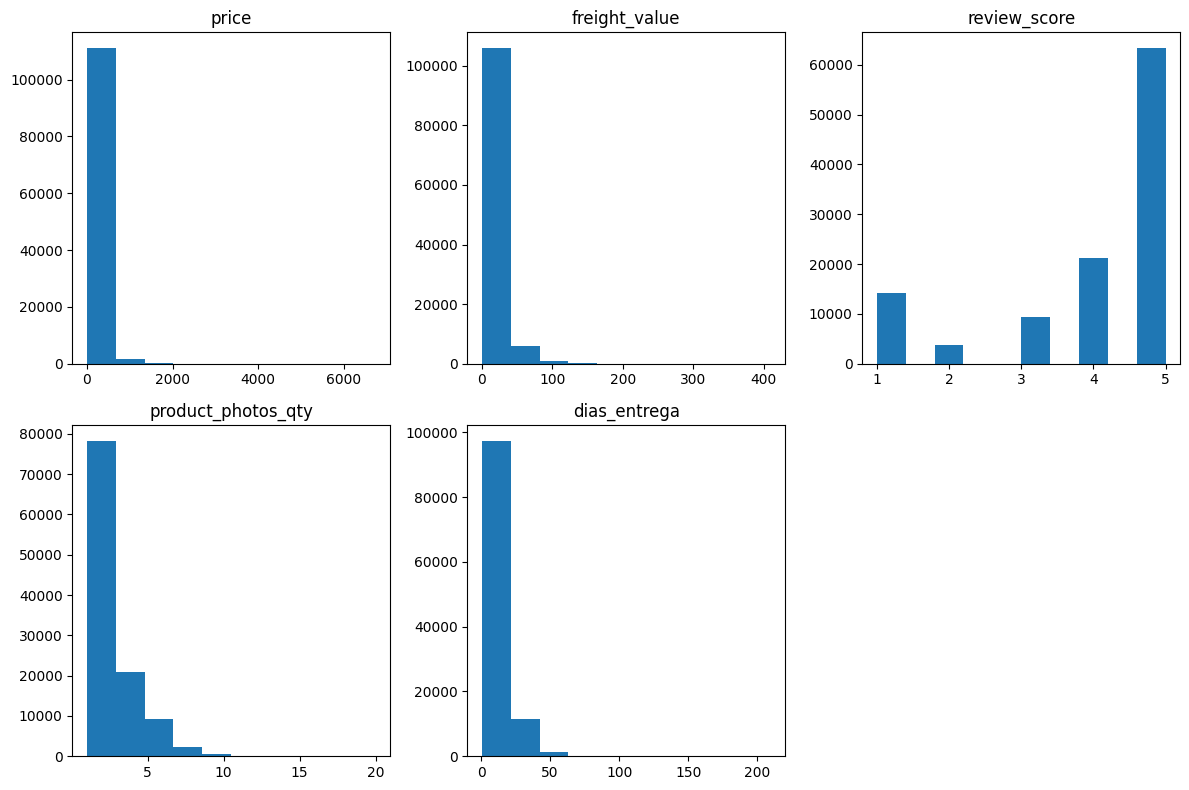

In [626]:
# Sem log
plt.figure(figsize=(12, 8))
cols = ['price', 'freight_value', 'review_score', 'product_photos_qty', 'dias_entrega']

for x, col in enumerate(cols):
  plt.subplot(2, 3, x+1)
  plt.hist(dados[col])
  plt.title(col)

plt.tight_layout()
plt.show()

#### **Questão 4:** Você nota que os histogramas de preço, frete e dias de entrega apresentam uma distribuição com a grande maioria das ocorrências à esquerda e uma cauda longa à direita. Identifique qual a **transformação** mais promissora para esses casos, aplique-a, retrace os histogramas e explique o que melhorou.

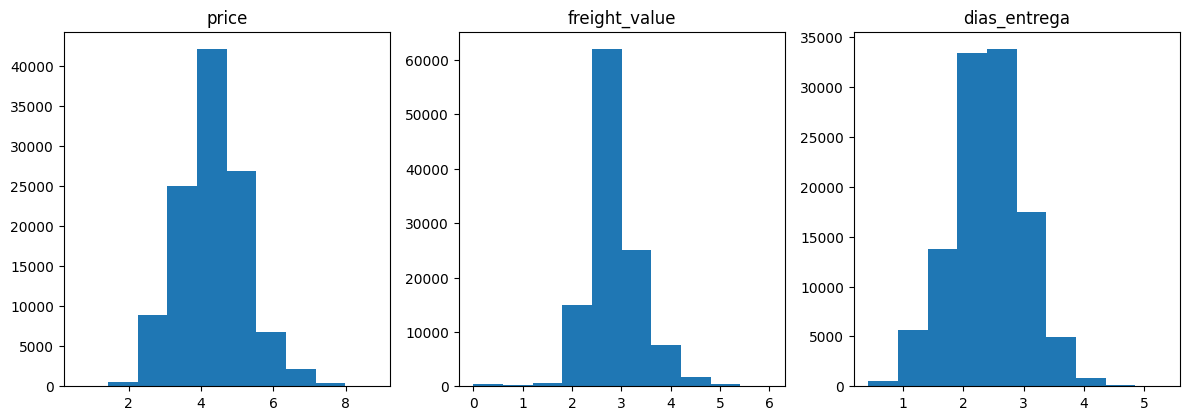

In [627]:
# Com log - Para melhorar a visuação da distrinuição no histogramas
cols = ['price', 'freight_value', 'dias_entrega']
dados_transformed = dados[cols].apply(np.log1p)
plt.figure(figsize=(12, 8))

for x, col in enumerate(cols):
  plt.subplot(2, 3, x+1)
  plt.hist(dados_transformed[col])
  plt.title(col)

plt.tight_layout()
plt.show()

**🗣️ Comentários:**

**Price**
* Preços seguem distribuição típica (muitos baratos, poucos caros).

**freight_value**
* Frete depende de fatores logísticos (distância, peso, valor do item);
* Provável correlação com price.

**review_score**
* Dados altamente enviesados (positivo);
* Clientes tendem a dar notas altas;
* Melhor visualização sem o log.

**product_photos_qty**
* A maioria dos produtos tem poucas fotos

**dias_entrega**
* Entrega rápida é padrão
* Atrasos são raros, mas impactantes

#### **Questão 5:** Você observa, pelo histograma de review_score (nota de avaliação do cliente, de 1 a 5), que o atributo tem forte viés para 4 e 5, e que isso pode induzir os modelos a uma interpretação artificialmente otimista. Ao mesmo tempo, especialistas em e-commerce te informam que as empresas estão mais preocupadas em saber se o cliente está ou não satisfeito, interpretando as notas 4 e 5 como satisfeito, e as restantes, como insatisfeito. **Binarize** (0 ou 1), portanto, o review_score, conforme essa interpretação.

In [628]:
dados['review_score_binarized'] = dados['review_score'].apply(lambda x: 1 if x >= 4 else 0)

/tmp/ipykernel_9783/2779926756.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dados['review_score_binarized'] = dados['review_score'].apply(lambda x: 1 if x >= 4 else 0)


In [629]:
dados_normed['review_score_binarized']

,review_score_binarized
0,1
1,1
2,1
3,1
4,1
...,...
113002,1
113003,1
113004,0
113005,1


#### **Questão 6:** Você nota que o atributo product_photos_qty (quantidade de fotos no anúncio do produto), também pode se beneficiar de quantização, pois sua distribuição é bastante desigual e esparsa. Especialistas em e-commerce te informam que, na prática, consideram uma foto, o mínimo necessário para um anúncio; 2 ou 3, uma quantidade razoável; 4 a 6, boa; e de 7 em diante, ótima. **Quantize o atributo** de acordo com a regra de negócio e retrace o histograma com os 4 bins resultantes.

In [630]:
def retorna_faixa_quantidade_fotos(x):
  match x:
    case 0:
      return 'Ruim'
    case 1:
      return 'Mínima'
    case 2 | 3:
        return 'Boa'
    case 4 | 5 | 6:
        return 'Muito Boa'
    case _:
        return 'Ótima'


dados['product_photos_qty_bin'] = dados['product_photos_qty'].apply(lambda x: retorna_faixa_quantidade_fotos(x))

/tmp/ipykernel_9783/997392038.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dados['product_photos_qty_bin'] = dados['product_photos_qty'].apply(lambda x: retorna_faixa_quantidade_fotos(x))


#### **Questão 7: Escalone os atributos numéricos** contínuos transformados na Questão 4. Escolha uma função de escalonamento, justifique e aplique a transformação. Compare os boxplots dos 3 atributos antes e depois da normalização.

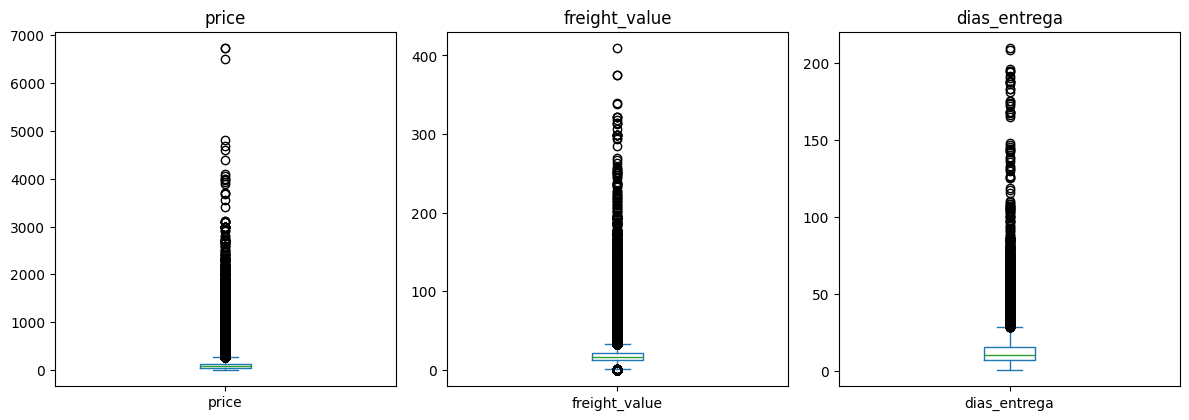

In [631]:
# Antes da normalização
cols = ['price', 'freight_value', 'dias_entrega']
plt.figure(figsize=(12, 8))

for x, col in enumerate(cols):
  plt.subplot(2, 3, x+1)
  dados[col].plot.box()
  plt.title(col)

plt.tight_layout()
plt.show()

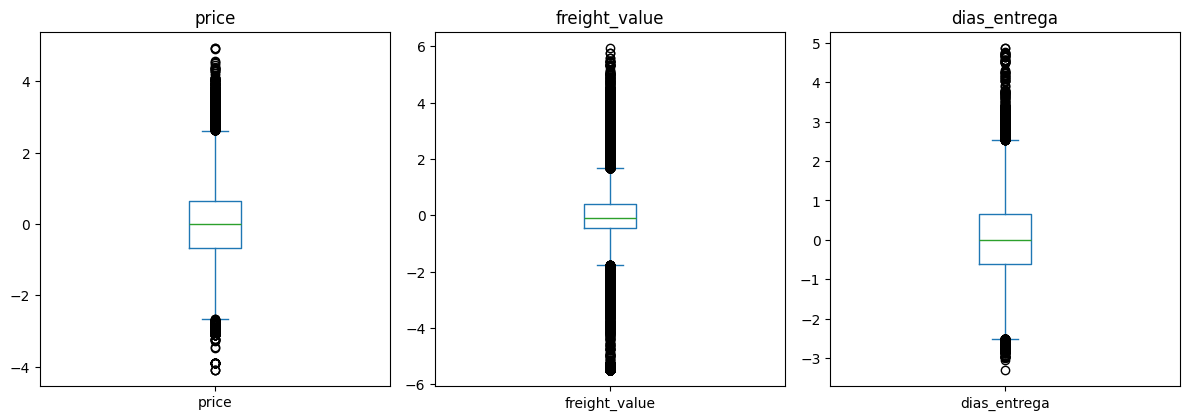

In [632]:
dados_normed = dados.copy()

dados_normed[cols] = dados_normed[cols].apply(np.log1p) # Escala logarítmica (para normalizar a distribuição)

scaler = StandardScaler()
dados_normed[cols] = scaler.fit_transform(dados_normed[cols])

# Depois da normalização
plt.figure(figsize=(12, 8))

for x, col in enumerate(cols):
  plt.subplot(2, 3, x+1)
  dados_normed[col].plot.box()
  plt.title(col)

plt.tight_layout()
plt.show()

**🗣️ Comentários:**

**Antes x Depois**

Quando falamos do **antes**, conseguimos afirmar que:
* Presença de outliers
* Centralidade dos dados nos valores baixos (pico do lado esquerdo e cauda longa a direita)

Olhando para o **depois** vemos:
* Distribuição dos dados mais uniforme
* Sem cauda longa a direita
* Ainda pode-se esperar outliers (mas sem tanto impacto)

**Escala logarítmica**

A escala logarítmica diminui a diferença entra valores muito alto em relação aos baixos, reduzindo o viés que estes outliers dariam aos dados.

**Standard Scaler**

Por fim, para normalizar os dados (pensando em aplicá-los em modelos de ML), aplicamos o Standard Scaler.

## 💬 PARTE III | Prática com dados textuais

#### **Questão 8:** A coluna 'review_comment_message' contém as avaliações de produtos feitas pelos clientes. Realize uma limpeza básica do atributo e **vetorize-o com n-gramas** de primeira e segunda ordem (`ngram_range=(1,2)`), removendo stopwords com lista adequada ao idioma. Imprima o número de tokens obtido, bem como uma amostra com cerca de 100 n-gramas do seu vetor de n-gramas resultante.

***Dica:** utilize `strip_accents` na vetorização para remover acentos, evitando, por exemplo, que “otimo” e “ótimo” assumam tokens diferentes.*

In [633]:
dados_normed['review_comment_message']

,review_comment_message
0,NaN
1,NaN
2,NaN
3,NaN
4,O baratheon è esxelente Amo adoro o baratheon
...,...
113002,NaN
113003,NaN
113004,Esperava qualidade no atendimento e estou tend...
113005,NaN


In [634]:
dados_normed[
    dados_normed['review_comment_message'].notna() &
    (dados_normed['review_comment_message'].str.strip() != '')
]

,customer_unique_id,seller_id,product_id,order_item_id,shipping_limit_date,customer_zip_code_prefix,customer_city,customer_state,order_status,order_purchase_timestamp,...,product_photos_qty,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp,geolocation_lat,dias_entrega,review_score_binarized,product_photos_qty_bin
4,345ecd01c38d18a9036ed96c73b8d066,4a3ca9315b744ce9f8e9374361493884,9391a573abe00141c56e38d84d7d5b3b,1,2018-07-31 10:10:09,13056,campinas,SP,delivered,2018-07-29 09:51:30,...,1.0,5.0,a melhor nota,O baratheon è esxelente Amo adoro o baratheon,2018-08-10 00:00:00,2018-08-17 01:59:52,-22.987222,0.175882,1,Mínima
5,4c93744516667ad3b8f1fb645a3116a4,8f2ce03f928b567e3d56181ae20ae952,0be701e03657109a8a4d5168122777fb,1,2017-09-20 18:25:11,89254,jaragua do sul,SC,delivered,2017-09-14 18:14:31,...,2.0,5.0,NaN,Loja responsável,2017-09-29 00:00:00,2017-10-01 21:52:53,-26.468503,0.480715,1,Boa
8,1175e95fb47ddff9de6b2b06188f7e0d,95e03ca3d4146e4011985981aeb959b9,08401f48b67a852d06105725c3013eff,1,2018-01-30 12:56:32,81560,curitiba,PR,delivered,2018-01-18 12:35:44,...,5.0,5.0,NaN,chegou antes do prometido,2018-01-27 00:00:00,2018-01-30 19:18:27,-25.496853,-0.344066,1,Muito Boa
9,9afe194fb833f79e300e37e580171f22,0241d4d5d36f10f80c644447315af0bd,78efe838c04bbc568be034082200ac20,1,2018-01-12 11:35:27,30575,belo horizonte,MG,delivered,2018-01-08 11:22:34,...,1.0,5.0,NaN,"ótimo, entregou antes da data prevista.",2018-01-14 00:00:00,2018-01-16 19:29:39,-19.970076,-0.998580,1,Mínima
10,2a7745e1ed516b289ed9b29c7d0539a5,b6e1504972665f739dec4facb9943775,6b874ff4c71d18e91079b40396bf176a,1,2017-12-01 18:01:20,39400,montes claros,MG,delivered,2017-11-27 17:23:20,...,8.0,5.0,NaN,Td certo.Produto e prazo de entrega.,2017-12-09 00:00:00,2017-12-10 18:58:15,-16.718833,0.141140,1,Ótima
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
112992,4452b8ef472646c4cc042cb31a291f3b,128639473a139ac0f3e5f5ade55873a5,5d66715cc928aadd0074f61332698593,1,2017-11-30 02:31:41,12236,sao jose dos campos,SP,delivered,2017-11-25 00:31:20,...,1.0,4.0,NaN,Gostei do produto,2017-12-05 00:00:00,2017-12-06 01:09:31,-23.246561,-0.052261,1,Mínima
112997,ca186065de6e2d01cfc99763e6d62048,4c18691b6037662be2df78a765d98ab5,c65f71634a9d0de5b4a1d7dbb6d3ae01,1,2018-06-14 02:55:19,99150,marau,RS,delivered,2018-06-05 13:33:19,...,3.0,5.0,RECOMENDADO,ÓTIMO,2018-06-14 00:00:00,2018-06-14 20:57:12,-28.459525,-0.338892,1,Boa
113001,4b5820135d360a45552b5163835b1d89,e06f09ec0a4aca210779cf1cfc63cf19,c770c3d5ab511e88a96d387bdb0b6ce0,1,2018-01-03 00:17:27,35500,divinopolis,MG,delivered,2017-12-17 23:13:41,...,2.0,1.0,NaN,tenho reclamaçoes quanto ao produto. nao atend...,2018-01-05 00:00:00,2018-01-05 22:33:22,-20.146615,0.839473,0,Boa
113004,e9f50caf99f032f0bf3c55141f019d99,d9e7e7778b32987280a6f2cb9a39c57d,7a5d2e1e131a860ae7d18f6fffa9d689,1,2018-04-12 20:30:03,60115,fortaleza,CE,delivered,2018-04-08 20:11:50,...,1.0,1.0,Chateada,Esperava qualidade no atendimento e estou tend...,2018-05-04 00:00:00,2018-05-08 01:41:07,-3.744128,1.740246,0,Mínima


In [635]:
nltk.download('stopwords')
stopwords_pt = stopwords.words('portuguese')

bow = CountVectorizer(ngram_range=(1, 2), strip_accents='ascii', stop_words=stopwords_pt)
corpus = dados_normed['review_comment_message'].fillna('')
bow.fit_transform(corpus)

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
/usr/local/lib/python3.12/dist-packages/sklearn/feature_extraction/text.py:402: UserWarning: Your stop_words may be inconsistent with your preprocessing. Tokenizing the stop words generated tokens ['ate', 'eramos', 'estao', 'estavamos', 'estiveramos', 'estivessemos', 'foramos', 'fossemos', 'ha', 'hao', 'houveramos', 'houverao', 'houveriamos', 'houvessemos', 'ja', 'nao', 'sao', 'sera', 'serao', 'seriamos', 'so', 'tambem', 'tera', 'terao', 'teriamos', 'tinhamos', 'tiveramos', 'tivessemos', 'voce', 'voces'] not in stop_words.
  warnings.warn(


<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 666525 stored elements and shape (113007, 122813)>

In [636]:
print(f"Vocabulário: {len(bow.vocabulary_)}\n")

print('n-grams:')
words = bow.get_feature_names_out()
words[:100]

Vocabulário: 122813

n-grams:


array(['00', '00 00', '00 20', '00 210', '00 35', '00 50', '00 55',
       '00 60', '00 80', '00 achei', '00 ainda', '00 bacana', '00 barato',
       '00 cada', '00 diferenca', '00 entanto', '00 entao',
       '00 entregaram', '00 fico', '00 frente', '00 frete', '00 gostaria',
       '00 hs', '00 inferior', '00 mandaram', '00 manha', '00 maximo',
       '00 mesma', '00 metro', '00 miopia', '00 mm', '00 nao',
       '00 opiniao', '00 outro', '00 paguei', '00 positivo', '00 preciso',
       '00 promocao', '00 quase', '00 reais', '00 recebi', '00 retirar',
       '00 sendo', '00 tiracao', '00 vale', '00 veio', '00 vista', '000',
       '000 btu', '000 btus', '000 ml', '000580', '000580 ajudante',
       '001063', '001063 iten', '001689', '001689 aguardo', '003566',
       '003566 ja', '003570', '003570 controle', '00m', '00m 70m', '00x',
       '00x 20', '00x2', '00x2 50', '00x2 50mts', '00x2 80', '01',
       '01 01', '01 02', '01 03', '01 05', '01 06', '01 07', '01 08',
       '01 09', 

#### **Questão 9:** Realize a vetorização e redimensionamento da mesma feature 'review_comment_message' utilizando a técnica **TF-IDF**. Compare e comente os resultados.

In [637]:
tfidf_vectorizer = TfidfVectorizer(
  ngram_range=(1, 2),
  strip_accents='ascii',
  stop_words=stopwords_pt
)

tfidf_matrix = tfidf_vectorizer.fit_transform(corpus)
tfidf_feature_names = tfidf_vectorizer.get_feature_names_out()

In [638]:
print(f"Vocabulário: {len(tfidf_vectorizer.vocabulary_)}\n")

print('n-grams:')
tfidf_feature_names[:100]

Vocabulário: 122813

n-grams:


array(['00', '00 00', '00 20', '00 210', '00 35', '00 50', '00 55',
       '00 60', '00 80', '00 achei', '00 ainda', '00 bacana', '00 barato',
       '00 cada', '00 diferenca', '00 entanto', '00 entao',
       '00 entregaram', '00 fico', '00 frente', '00 frete', '00 gostaria',
       '00 hs', '00 inferior', '00 mandaram', '00 manha', '00 maximo',
       '00 mesma', '00 metro', '00 miopia', '00 mm', '00 nao',
       '00 opiniao', '00 outro', '00 paguei', '00 positivo', '00 preciso',
       '00 promocao', '00 quase', '00 reais', '00 recebi', '00 retirar',
       '00 sendo', '00 tiracao', '00 vale', '00 veio', '00 vista', '000',
       '000 btu', '000 btus', '000 ml', '000580', '000580 ajudante',
       '001063', '001063 iten', '001689', '001689 aguardo', '003566',
       '003566 ja', '003570', '003570 controle', '00m', '00m 70m', '00x',
       '00x 20', '00x2', '00x2 50', '00x2 50mts', '00x2 80', '01',
       '01 01', '01 02', '01 03', '01 05', '01 06', '01 07', '01 08',
       '01 09', 

**🗣️ Comentários:**

**`CountVectorizer` x `TF-IDF`**
Foram aplicadas as mesmas técnicas em ambos os modelos:
* ngram_range=(1, 2)
* remoção de acentos (strip_accents)
* stop_words (portugês)

Quando comparamos alguns ngrams de ambos os modelos (mesma amostra), o resultado é o mesmo (se não, muito parecido).

#### **Questão 10:** Utilizando os dados redimensionados da **Questão 9**, construa um modelo simples de classificação baseado em Regressão Logística, tendo como variável-alvo ("target") o atributo que você binarizou no review_score (onde 1 significa que a avaliação é interpretada como positiva e 0 como negativa). Lembre-se de considerar o balanceamento do volume dos dados de treino em relação à variável-alvo. Divida os dados entre treino (70%) e teste (30%), aplique a regressão aos dados de treino e meça a acurácia contra os dados de teste. Informe a acurácia obtida e crie um **gráfico de barras** exibindo os 30 maiores e os 30 menores coeficientes da regressão logística. Comente os resultados.

In [639]:
y = dados['review_score_binarized'] # 1 is a positive review and 0 is negative
X = tfidf_matrix

train_f, test_f, train_t, test_t = train_test_split(
  X, y, test_size=0.2, random_state=42, stratify=y
)

In [640]:
regressor = LogisticRegression()
regressor.fit(train_f, train_t)

regressor_pred = regressor.predict(test_f)
accuracy = accuracy_score(test_t, regressor_pred)
print("Accuracy:", accuracy)

Accuracy: 0.8664719936288824


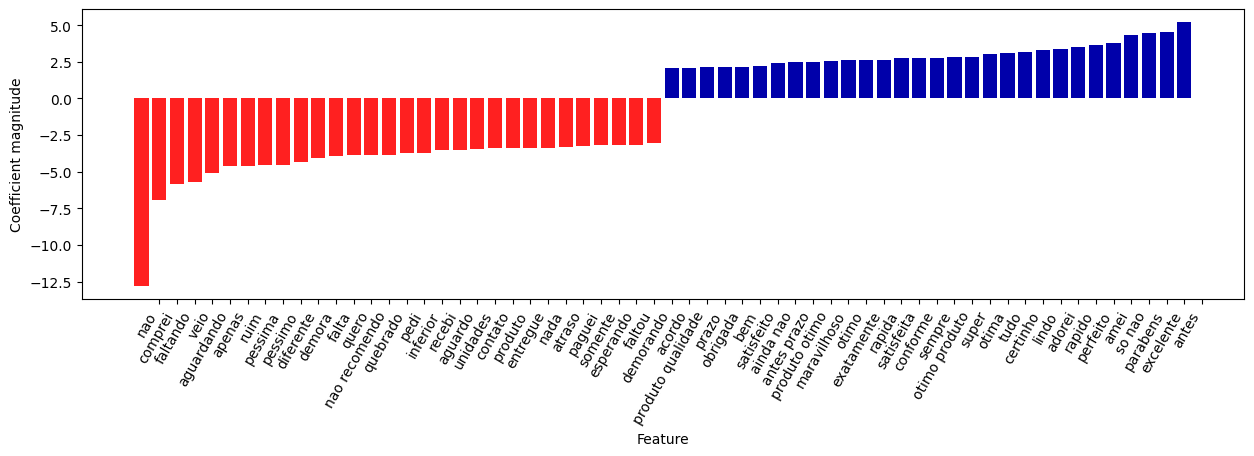

In [641]:
visualize_coefficients(
    regressor.coef_,
    tfidf_feature_names,
    n_top_features=30)

**🗣️ Comentários:**

De um lado, em vermelho, temos as palavras que mais influenciam na tomada decisão quando o comentário é negativo. Do outro, em azul, os termos mais decisivos quando a avaliação é positiva.

Quando olhamos os termos de cada grupo, percebemos a robustez do código, tanto na vetorização quando na aprendendizagem do modelo, pois o mesmo teve uma acurácio de 86,6% e está conseguindo categorizar os tokens de forma bem acertiva.

## ❓ PARTE IV | Prática com dados categóricos

#### **Questão 11:** Imprima uma lista com as variáveis categóricas do dataset e a cardinalidade de cada uma, em ordem decrescente, ou seja, da maior cardinalidade para a menor. Vetorize as de baixa cardinalidade (< 50 categorias) utlizando a técnica **One-Hot**.

In [642]:
categorical_cols = [
  'customer_city',
  'customer_state',
  'order_status',
  'product_category_name',
  'product_photos_qty_bin',
]

cardinality = []
for col in categorical_cols:
  cardinality.append(dados_normed[col].nunique())

cardinality.sort(reverse=True)
for (col, card) in zip(categorical_cols, cardinality):
  print(f"{col}: {card}")

customer_city: 4066
customer_state: 73
order_status: 27
product_category_name: 7
product_photos_qty_bin: 4


In [643]:
categorical_cols = [
  'order_status',
  'product_category_name',
  'product_photos_qty_bin',
]

encoder = OneHotEncoder(sparse_output=False)

features_ohe = encoder.fit_transform(dados_normed[categorical_cols])
names_ohe = encoder.get_feature_names_out()

dados_encoded = pd.DataFrame(features_ohe, columns=names_ohe)
dados_normed = pd.concat([dados_normed, dados_encoded], axis=1)

dados_normed = dados_normed.drop(columns=categorical_cols, axis=1)

dados_normed.head()

,customer_unique_id,seller_id,product_id,order_item_id,shipping_limit_date,customer_zip_code_prefix,customer_city,customer_state,order_purchase_timestamp,order_approved_at,...,product_category_name_sinalizacao_e_seguranca,product_category_name_tablets_impressao_imagem,product_category_name_telefonia,product_category_name_telefonia_fixa,product_category_name_utilidades_domesticas,product_category_name_nan,product_photos_qty_bin_Boa,product_photos_qty_bin_Muito Boa,product_photos_qty_bin_Mínima,product_photos_qty_bin_Ótima
0,861eff4711a542e4b93843c6dd7febb0,7c67e1448b00f6e969d365cea6b010ab,a9516a079e37a9c9c36b9b78b10169e8,1,2017-05-22 15:22:12,14409,franca,SP,2017-05-16 15:05:35,2017-05-16 15:22:12,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,290c77bc529b7ac935b93aa66c333dc3,b8bc237ba3788b23da09c0f1f3a3288c,4aa6014eceb682077f9dc4bffebc05b0,1,2018-01-18 20:58:32,9790,sao bernardo do campo,SP,2018-01-12 20:48:24,2018-01-12 20:58:32,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
2,060e732b5b29e8181a18229c7b0b2b5e,7c67e1448b00f6e969d365cea6b010ab,bd07b66896d6f1494f5b86251848ced7,1,2018-06-05 16:19:10,1151,sao paulo,SP,2018-05-19 16:07:45,2018-05-20 16:19:10,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,259dac757896d24d7702b9acbbff3f3c,7c67e1448b00f6e969d365cea6b010ab,a5647c44af977b148e0a3a4751a09e2e,1,2018-03-27 16:31:16,8775,mogi das cruzes,SP,2018-03-13 16:06:38,2018-03-13 17:29:19,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,345ecd01c38d18a9036ed96c73b8d066,4a3ca9315b744ce9f8e9374361493884,9391a573abe00141c56e38d84d7d5b3b,1,2018-07-31 10:10:09,13056,campinas,SP,2018-07-29 09:51:30,2018-07-29 10:10:09,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


#### **Questão 12:** Aplique Feature Hashing nas features de localização do cliente customer_zip_code_prefix e customer_city. O CEP (ZipCode) é uma feature de alta cardinalidade que tipicamente já contém ruído e erros de preenchimento, ensejando a aplicação de hashing. Empregue como nova dimensionalidade aproximadamente 2 × log₂(N), onde N é a cardinalidade original.

In [644]:
cols = ['customer_zip_code_prefix','customer_city']

for col in cols:
  print(f"{col:10} → {dados_normed[col].nunique():,} categorias")

customer_zip_code_prefix → 14,820 categorias
customer_city → 4,066 categorias


In [645]:
def row_to_features(row):
    feats = {}
    feats[f"customer_zip_code_prefix_{row['customer_zip_code_prefix']}"]   = 1
    feats[f"customer_city_{row['customer_city']}"] = 1
    return feats

feature_dicts = [row_to_features(row) for _, row in dados_normed.iterrows()]

In [646]:
N = (
    dados_normed['customer_zip_code_prefix'].nunique() +
    dados_normed['customer_city'].nunique()
)

# regra 2 * log2(N)
n_hash_features_raw = 2 * np.log2(N)

# ajustar para potência de 2
n_hash_features = 2 ** int(np.ceil(np.log2(n_hash_features_raw)))

In [647]:
hasher = FeatureHasher(
    n_features=n_hash_features,
    input_type='dict',
)

X_hashed = hasher.transform(feature_dicts)

print("\nHashed matrix shape:", X_hashed.shape)

X_hashed


Hashed matrix shape: (113007, 32)


<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 221953 stored elements and shape (113007, 32)>

In [648]:
X_hashed_df = pd.DataFrame.sparse.from_spmatrix(
    X_hashed,
    columns=[f"hash_{i}" for i in range(X_hashed.shape[1])]
)

dados_normed = pd.concat([dados_normed.reset_index(drop=True), X_hashed_df], axis=1)

dados_normed = dados_normed.drop(columns=cols, axis=1)


#### **Questão 13:** Aplique Bin Counting nas features identificadoras agregáveis: product_id, customer_unique_id e seller_id.

In [649]:
cols = ['product_id', 'customer_unique_id', 'seller_id']

for col in cols:
    bin_counts = dados_normed[col].value_counts()
    dados_normed[col] = dados_normed[col].map(bin_counts)

dados_normed[cols].head()

,product_id,customer_unique_id,seller_id
0,59,1,1372
1,47,1,47
2,10,1,1372
3,21,1,1372
4,4,1,2007


#### **Questão 14:** Aplique PCA no dataset resultante das transformações efetuadas até o momento, removendo antes as features textuais, as features de datas, e as features originais das transformações que você realizou. Remova o review_score binarizado, que deverá ser usado como variável-alvo do PCA. Não esqueça de remover também o review_score original para não haver vazamento de informação para o modelo. Execute o PCA para k componentes tal que k explique 95% da variância dos dados.

In [650]:
cols_to_remove = [
    'shipping_limit_date', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_estimated_delivery_date', 'order_delivered_customer_date',
    'review_score', 'product_photos_qty', 'product_photos_qty', 'product_photos_qty', 'review_comment_message', 'review_creation_date', 'review_comment_title', 'review_answer_timestamp',
    'customer_state'
]

dados_normed = dados_normed.drop(columns=cols_to_remove)

In [651]:
dados_normed.fillna(0, inplace=True)

In [652]:
results = []
k_values = np.linspace(1, 10, 10, dtype=int)

for k in k_values:
  pca = PCA(n_components=k)

  pca.fit(dados_normed)
  pca.transform(dados_normed)

  variancia = pca.explained_variance_ratio_
  variancia_acumulada = variancia.cumsum()
  results.append({
    'k':k,
    'variancia': variancia,
    'variancia_acumulada':variancia_acumulada[-1]
  })

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:921: UserWarning: pandas.DataFrame with sparse columns found.It will be converted to a dense numpy array.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:921: UserWarning: pandas.DataFrame with sparse columns found.It will be converted to a dense numpy array.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:921: UserWarning: pandas.DataFrame with sparse columns found.It will be converted to a dense numpy array.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:921: UserWarning: pandas.DataFrame with sparse columns found.It will be converted to a dense numpy array.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:921: UserWarning: pandas.DataFrame with sparse columns found.It will be converted to a dense numpy array.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklea

In [653]:
dados_results = pd.DataFrame(results)
dados_results

,k,variancia,variancia_acumulada
0,1,[0.9844693170108896],0.984469
1,2,"[0.9844693170108896, 0.015407551131514097]",0.999877
2,3,"[0.9844693170108896, 0.015407551131514097, 9.5...",0.999972
3,4,"[0.9844693170108896, 0.015407551131514097, 9.5...",0.999980
4,5,"[0.9844693170108896, 0.015407551131514097, 9.5...",0.999984
5,6,"[0.9844693170108896, 0.015407551131514097, 9.5...",0.999986
6,7,"[0.9844693170108896, 0.015407551131514097, 9.5...",0.999988
7,8,"[0.9844693170108896, 0.015407551131514097, 9.5...",0.999989
8,9,"[0.9844693170108896, 0.015407551131514097, 9.5...",0.999990
9,10,"[0.9844693170108896, 0.015407551131514097, 9.5...",0.999990


#### **Questão 15:** Trace um gráfico de barras da variância explicada em função de k.

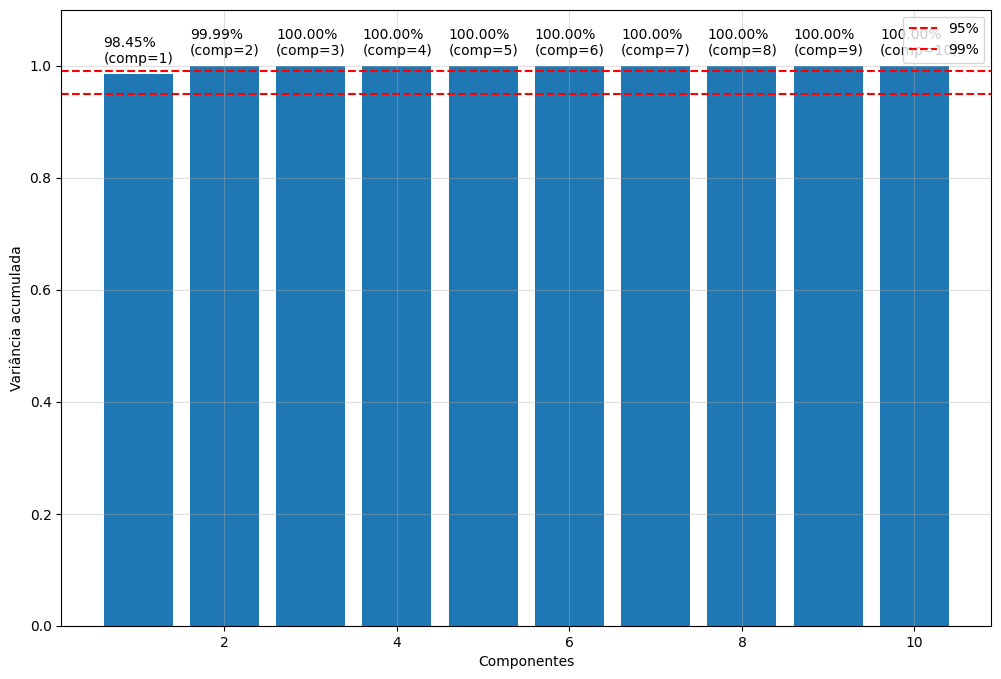

In [654]:
plt.figure(figsize=(12, 8))
plt.bar(
    dados_results['k'],
    dados_results['variancia_acumulada']
)

plt.axhline(0.95, linestyle='--', label='95%', color='red')
plt.axhline(0.99, linestyle='--', label='99%', color='red')

for x, y in zip(dados_results['k'], dados_results['variancia_acumulada']):
  plt.annotate(f"{y:.2%}\n(comp={x})", (x-0.4, y+0.02))

plt.ylim(0,1.1)
plt.xlabel("Componentes")
plt.ylabel("Variância acumulada")
plt.grid(alpha=0.4)
plt.legend()
plt.show()

#### **Questão 16:** Trace um gráfico de dispersão (scatter) bidimensional pontuando as instâncias dos dados no plano dos dois maiores componentes principais, colorindo as amostras de acordo com o review_score binarizado. Opcionalmente, trace também o gráfico de dispersão tridimensional, com os três maiores componentes principais.

In [659]:
X = dados_normed.drop(columns=['review_score_binarized'])
y = dados_normed['review_score_binarized']

In [660]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

df_pca = pd.DataFrame({
    'PC1': X_pca[:, 0],
    'PC2': X_pca[:, 1],
    'review_bin': y
})

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:921: UserWarning: pandas.DataFrame with sparse columns found.It will be converted to a dense numpy array.
  warnings.warn(


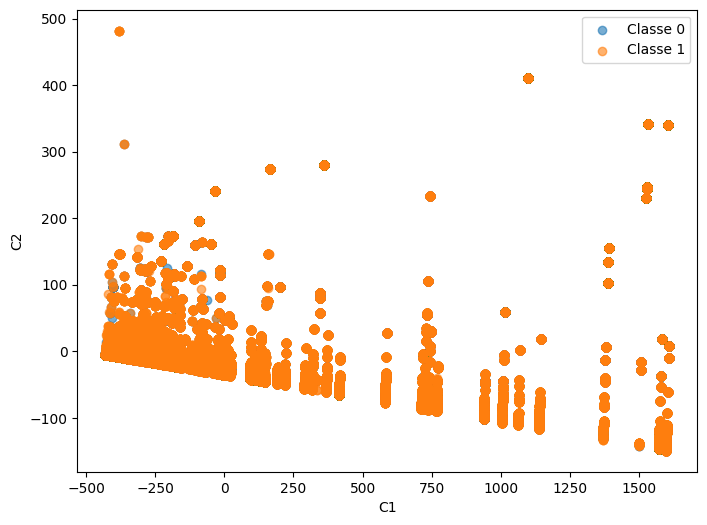

In [662]:
plt.figure(figsize=(8,6))

for classe in [0, 1]:
    subset = df_pca[df_pca['review_bin'] == classe]

    plt.scatter(
        subset['PC1'],
        subset['PC2'],
        label=f"Classe {classe}",
        alpha=0.6
    )

plt.xlabel("C1")
plt.ylabel("C2")

plt.legend()
plt.show()